# Ch06_ECG5000_Autoencoder

『실전! AI 프로젝트 완주의 기술』의 인쇄용 PDF에 수록된 코드에서 추출한 학습용 노트북입니다.

**주의:** 인쇄물에서 자동 추출된 초안입니다. 일부 조판 문자·줄바꿈·별도 데이터 경로가 원본 소스와 다를 수 있으므로 실행 전 확인하세요. 각 코드 셀 위에 인쇄본 페이지를 표시했습니다. 데이터 다운로드 및 패키지 설치는 필요한 경우 직접 진행해야 합니다. 출판 전 실행 검증본으로 간주하지 마세요.

**인쇄본 154쪽 — 코드**

In [1]:
import numpy as np
import pandas as pd
url = 'https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv'
dataframe = pd.read_csv(url, header=None)
raw_data = dataframe.values
print(raw_data.shape)

(4998, 141)


**인쇄본 154쪽 — 출력 예시 (실행 코드 아님)**

```text
(4998, 141)
```

**인쇄본 154쪽 — 코드**

In [2]:
X = raw_data[:, :-1]
y = raw_data[:, -1].astype(int)
print(X.shape)
print(np.bincount(y))

(4998, 140)
[2079 2919]


**인쇄본 154쪽 — 출력 예시 (실행 코드 아님)**

```text
(4998, 140)
[2079 2919]
```

**인쇄본 154쪽 — 코드**

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=0, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=0, stratify=y_temp
)
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(2998, 140)
(1000, 140)
(1000, 140)


**인쇄본 155쪽 — 출력 예시 (실행 코드 아님)**

```text
(2998, 140)
(1000, 140)
(1000, 140)
```

**인쇄본 155쪽 — 코드**

In [4]:
normal_train_raw = X_train[y_train == 1]
print(normal_train_raw.shape)

(1751, 140)


**인쇄본 155쪽 — 출력 예시 (실행 코드 아님)**

```text
(1751, 140)
```

**인쇄본 155쪽 — 코드**

In [5]:
min_val = np.min(normal_train_raw)
max_val = np.max(normal_train_raw)
X_train = (X_train - min_val) / (max_val - min_val)
X_val = (X_val - min_val) / (max_val - min_val)
X_test = (X_test - min_val) / (max_val - min_val)

**인쇄본 156쪽 — 코드**

In [6]:
normal_train_data = X_train[y_train == 1]
normal_val_data = X_val[y_val == 1]
anomaly_val_data = X_val[y_val == 0]
normal_test_data = X_test[y_test == 1]
anomaly_test_data = X_test[y_test == 0]
print(normal_train_data.shape)

(1751, 140)


**인쇄본 156쪽 — 출력 예시 (실행 코드 아님)**

```text
(1751, 140)
```

**인쇄본 156쪽 — 코드** 

In [7]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense
autoencoder = Sequential([
    Input(shape=(140,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(16, activation='relu'),
    Dense(32, activation='relu'),
    Dense(140)
])

**인쇄본 157쪽 — 코드** — 

In [8]:
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)
history = autoencoder.fit(
    normal_train_data,
    normal_train_data,
    epochs=50,
    batch_size=64,
    validation_data=(normal_val_data, normal_val_data),
    shuffle=True
)

Epoch 1/50
28/28 [==============================] - 3s 15ms/step - loss: 0.3195 - val_loss: 0.2350
Epoch 2/50
28/28 [==============================] - 0s 7ms/step - loss: 0.1190 - val_loss: 0.0341
Epoch 3/50
28/28 [==============================] - 0s 8ms/step - loss: 0.0142 - val_loss: 0.0039
Epoch 4/50
28/28 [==============================] - 0s 7ms/step - loss: 0.0023 - val_loss: 0.0016
Epoch 5/50
28/28 [==============================] - 0s 7ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 6/50
28/28 [==============================] - 0s 8ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 7/50
28/28 [==============================] - 0s 7ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 8/50
28/28 [==============================] - 0s 7ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 9/50
28/28 [==============================] - 0s 8ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 10/50
28/28 [==============================] - 0s 8ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 11/50
28/28 

**인쇄본 158쪽 — 코드**

In [9]:
normal_reconstructed = autoencoder.predict(normal_val_data)
rmse = np.sqrt(
  np.mean((normal_val_data - normal_reconstructed)**2)
)
nrmse = rmse / np.std(normal_val_data)
print(rmse)
print(nrmse)

19/19 [==============================] - 0s 1ms/step
0.0387862197464078
0.4693163741641256


**인쇄본 158쪽 — 출력 예시 (실행 코드 아님)**

```text
0.019
0.28
```

**인쇄본 159쪽 — 코드**

In [10]:
val_reconstructed = autoencoder.predict(X_val)
val_error = np.sqrt(
    np.mean((X_val - val_reconstructed)**2, axis=1)
)
normal_error = val_error[y_val == 1]
anomaly_error = val_error[y_val == 0]
print(np.mean(normal_error))
print(np.mean(anomaly_error))

32/32 [==============================] - 0s 1ms/step
0.03531437463809804
0.08699605279066897


**인쇄본 159쪽 — 출력 예시 (실행 코드 아님)**

```text
0.019
0.058
```

**인쇄본 160쪽 — 코드**

In [11]:
threshold = 0.041

**인쇄본 160쪽 — 코드**

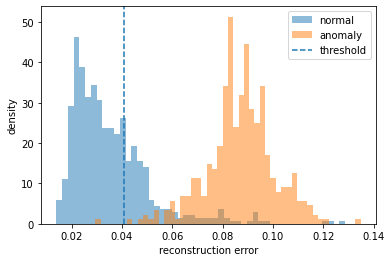

In [12]:
import matplotlib.pyplot as plt
plt.hist(
    normal_error, bins=50, alpha=0.5,
    density=True, label='normal'
)
plt.hist(
    anomaly_error, bins=50, alpha=0.5,
    density=True, label='anomaly'
)
plt.axvline(
    threshold, linestyle='--',
    label='threshold'
)
plt.xlabel('reconstruction error')
plt.ylabel('density')
plt.legend()
plt.show()

**인쇄본 161쪽 — 코드**

In [13]:
test_reconstructed = autoencoder.predict(X_test)
test_error = np.sqrt(
    np.mean((X_test - test_reconstructed)**2, axis=1)
)

32/32 [==============================] - 0s 1ms/step


**인쇄본 162쪽 — 코드**

In [14]:
y_pred = (test_error > threshold).astype(int)
y_true = (y_test == 0).astype(int)

**인쇄본 162쪽 — 코드**

In [15]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
print(cm)

[[434 150]
 [  0 416]]


**인쇄본 162쪽 — 출력 예시**

```text
[[568  16]
 [  6 410]]
```

**인쇄본 163쪽 — 코드**

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
print(accuracy_score(y_true, y_pred))
print(precision_score(y_true, y_pred))
print(recall_score(y_true, y_pred))
print(f1_score(y_true, y_pred))

0.85
0.734982332155477
1.0
0.8472505091649695


**인쇄본 163쪽 — 출력 예시 (실행 코드 아님)**

```text
0.978
0.962
0.986
0.974
```